# Лабораторная работа №2
## Морфологический анализ, POS-tagging и извлечение синтаксических структур

**Датасет:** RuHateBe, продолжение лабораторной №1.

**Цель:** исследовать грамматические признаки и синтаксические связи в форумных репликах.

**Статус:** выполнены загрузка, аудит корпуса, POS-разметка и извлечение морфологических признаков. Распределения POS и сравнение классов выполнены. Разобраны шесть ошибок тэггера. Построены деревья зависимостей для 10 предложений. Реализовано извлечение пар «подлежащее + действие». Топ-20 пар посчитан и показан с контекстами. Алгоритм анафоры продемонстрирован на 10 репликах с контекстом.

План: данные → POS и морфология → распределения по классам → ошибки тэггера → 10 деревьев → извлечение пар → топ-20 → анафора → выводы.

## 1. Окружение и параметры

Свое окружение `lab2/.venv`. Версии spaCy и русской модели `ru_core_news_sm` закреплены в `lab2/uv.lock`.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

TEXT_COL = "Reply 2 original"
LABEL_COL = "target_group"
CONTEXT_COL = "Reply 1 original"
ANALYSIS_LABEL_COL = "target_group_analysis"

DATA_PATH = Path("data/balanced_RUHABE.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../data/balanced_RUHABE.csv")

pd.set_option("display.max_colwidth", 140)

## 2. Загрузка и проверка корпуса

Анализируем `Reply 2 original`, контекст — `Reply 1 original`.
Метка `target_group` обозначает объект агрессии, а не тональность.
Для сравнения объединяем `migrant` и `migrants`, сохраняя исходную метку.
Повторы оставляем: одинаковые реплики могут иметь разные контексты и классы.
Текст сохраняем с пунктуацией и местоимениями.

In [2]:
raw = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig", index_col=0)
corpus = raw[[TEXT_COL, LABEL_COL, CONTEXT_COL]].copy()
corpus.insert(0, "source_row_id", raw.index)

corpus = corpus.dropna(subset=[TEXT_COL])
corpus = corpus[corpus[TEXT_COL].str.strip() != ""].reset_index(drop=True)
corpus[ANALYSIS_LABEL_COL] = corpus[LABEL_COL].replace({"migrant": "migrants"})

print(f"Исходных строк: {len(raw)}")
print(f"Строк для анализа: {len(corpus)}")
print(f"Уникальных реплик: {corpus[TEXT_COL].nunique()}")
display(corpus[[TEXT_COL, LABEL_COL, CONTEXT_COL]].isna().sum().rename("Пропуски"))
display(corpus[ANALYSIS_LABEL_COL].value_counts().rename("Реплик в классе"))

Исходных строк: 10382
Строк для анализа: 10382
Уникальных реплик: 7274


Reply 2 original    0
target_group        0
Reply 1 original    0
Name: Пропуски, dtype: int64

target_group_analysis
man           2456
women         2025
other         1917
born_place    1827
lgbt          1180
migrants       556
child          421
Name: Реплик в классе, dtype: int64

## 3. POS-tagging и морфологические признаки

In [3]:
import spacy

nlp = spacy.load("ru_core_news_sm", disable=["ner"])
docs = list(nlp.pipe(corpus[TEXT_COL], batch_size=64))
print(f"Обработано реплик: {len(docs)}")

Обработано реплик: 10382


In [4]:
rows = []
for i, doc in enumerate(docs):
    row = corpus.iloc[i]
    for token in doc:
        if token.is_space:
            continue
        rows.append({
            "document_id": row["source_row_id"],
            "target_group_analysis": row[ANALYSIS_LABEL_COL],
            "text": token.text,
            "lemma": token.lemma_,
            "pos": token.pos_,
            "morph": str(token.morph),
        })

tokens = pd.DataFrame(rows)

In [5]:
print(f"Токенов без пробелов, включая пунктуацию: {len(tokens)}")
display(tokens.head(30))

Токенов без пробелов, включая пунктуацию: 345689


,document_id,target_group_analysis,text,lemma,pos,morph
0,0,women,Слышишь,слышать,VERB,Aspect=Imp|Mood=Ind|Number=Sing|Person=Second|Tense=Pres|VerbForm=Fin|Voice=Act
1,0,women,блядь,блядь,NOUN,Animacy=Inan|Case=Acc|Gender=Masc|Number=Sing
2,0,women,заткни,заткни,PROPN,Animacy=Anim|Case=Dat|Gender=Masc|Number=Sing
3,0,women,свой,свой,DET,Case=Acc|Gender=Masc|Number=Sing
4,0,women,ебальник,ебальник,NOUN,Animacy=Inan|Case=Acc|Gender=Masc|Number=Sing
5,0,women,сука,сук,NOUN,Animacy=Inan|Case=Gen|Gender=Masc|Number=Sing
6,1,women,я,я,PRON,Case=Nom|Number=Sing|Person=First
7,1,women,высказал,высказать,VERB,Aspect=Perf|Gender=Masc|Mood=Ind|Number=Sing|Tense=Past|VerbForm=Fin|Voice=Act
8,1,women,предположение,предположение,NOUN,Animacy=Inan|Case=Acc|Gender=Neut|Number=Sing
9,1,women,что,что,SCONJ,


## 4. Распределение частей речи

Считаем токены без `PUNCT` и `SPACE`. Символы `SYM` и неизвестные `X` учитываем.
Доли по классам считаем от числа учитываемых токенов каждого класса. Повторные реплики сохраняются.

,Количество,"Доля, %"
pos,,
NOUN,76182,25.50
VERB,42284,14.16
ADP,28266,9.46
PRON,27718,9.28
ADJ,22279,7.46
ADV,20927,7.01
PROPN,20681,6.92
PART,17341,5.81
CCONJ,13877,4.65


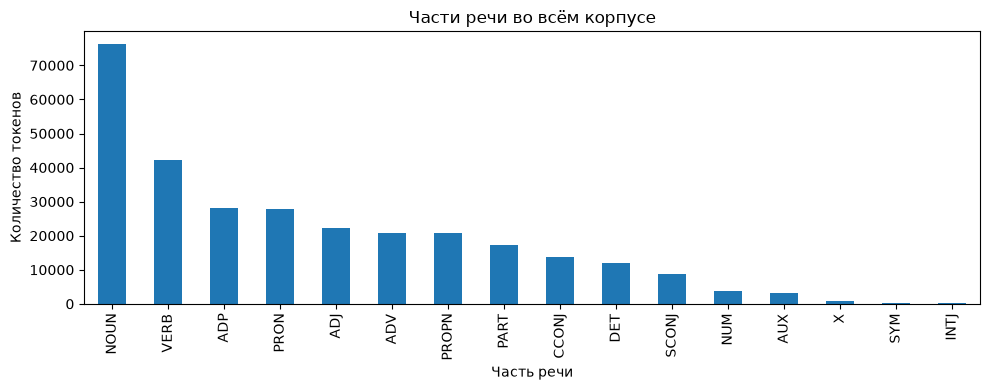

In [6]:
words = tokens[~tokens["pos"].isin(["PUNCT", "SPACE"])]
pos_counts = words["pos"].value_counts()
pos_summary = pos_counts.to_frame("Количество")
pos_summary["Доля, %"] = (pos_counts / len(words) * 100).round(2)
display(pos_summary)

pos_counts.plot.bar(figsize=(10, 4), title="Части речи во всём корпусе")
plt.xlabel("Часть речи")
plt.ylabel("Количество токенов")
plt.tight_layout()
plt.show()

pos,NOUN,ADJ,VERB,PRON,INTJ
target_group_analysis,,,,,
born_place,26.04,7.12,13.99,8.42,0.03
child,25.61,7.49,14.23,9.23,0.03
lgbt,25.83,7.55,14.38,9.19,0.05
man,25.03,7.69,14.31,9.83,0.07
migrants,26.36,7.51,13.97,8.58,0.03
other,25.29,8.02,14.19,9.38,0.05
women,25.35,6.94,14.01,9.55,0.07


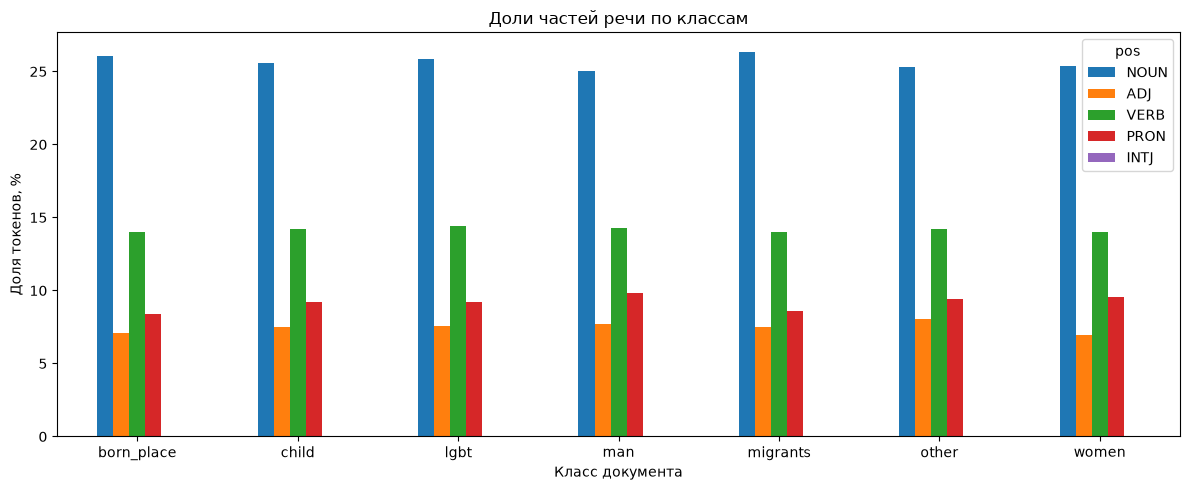

In [7]:
class_pos_counts = pd.crosstab(words[ANALYSIS_LABEL_COL], words["pos"])
class_pos_percent = class_pos_counts.div(class_pos_counts.sum(axis=1), axis=0) * 100

selected_pos = ["NOUN", "ADJ", "VERB", "PRON", "INTJ"]
display(class_pos_percent[selected_pos].round(2))

class_pos_percent[selected_pos].plot.bar(
    figsize=(12, 5), title="Доли частей речи по классам"
)
plt.xlabel("Класс документа")
plt.ylabel("Доля токенов, %")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

В каждом классе существительные занимают примерно четверть учитываемых токенов, глаголы — около 14%.
Прилагательных больше всего в `other` (8,02%), меньше всего в `women` (6,94%).
Местоимения чаще встречаются в `man` (9,83%), чем в `born_place` (8,42%).
Междометия редки во всех классах (0,03–0,07%). Это описательные различия между группами по объекту агрессии.

## 5. Ошибки готового тэггера

Выбираем вручную проверенные строки прямо из `tokens`.
Индекс слева — номер строки в `tokens`, `document_id` — идентификатор исходной реплики.
Причины ошибок предполагаем по контексту; разметку корпуса не меняем.

In [8]:
pos_error_review = tokens.loc[
    [2, 480, 1417, 1558, 43792, 69003],
    ["document_id", "text", "lemma", "pos", "morph"],
].copy()

pos_error_review["expected_lemma"] = ["заткнуть", "ахаха", "тупой", "запретить", "орать", "сейчас"]

pos_error_review["expected_pos"] = ["VERB", "INTJ", "ADJ", "VERB", "VERB", "ADV"]
pos_error_review["explanation"] = [
    "Заткни — повеление, глагол. Вероятно, мешают ругань и отсутствие пунктуации.",
    "Ахаха — запись смеха, междометие. Нестандартное написание с заглавной буквы.",
    "СУКА ТУПАЯ: прилагательное женского рода, а не имя собственное. Возможное влияние капса.",
    "Лемма — запретить. Запретите рожать: POS верный, но нужно Mood=Imp, Person=Second, Number=Plur; это призыв, не прошедшее время.",
    "Ору с тебя: глагол орать в сленговом значении, настоящее время, 1-е лицо, единственное число.",
    "Я щас смогу восстановить: щас означает сейчас, наречие времени. Разговорное написание.",
]

pos_error_review["context"] = pos_error_review["document_id"].map(
    corpus.set_index("source_row_id")[TEXT_COL]
)
with pd.option_context("display.max_colwidth", None):
    display(pos_error_review)

,document_id,text,lemma,pos,morph,expected_lemma,expected_pos,explanation,context
2,0,заткни,заткни,PROPN,Animacy=Anim|Case=Dat|Gender=Masc|Number=Sing,заткнуть,VERB,"Заткни — повеление, глагол. Вероятно, мешают ругань и отсутствие пунктуации.",Слышишь блядь заткни свой ебальник сука
480,11,Ахаха,ахаха,PROPN,Animacy=Anim|Case=Acc|Gender=Masc|Number=Sing,ахаха,INTJ,"Ахаха — запись смеха, междометие. Нестандартное написание с заглавной буквы.","Какие поручители, долбоёбина? Ахаха сука ебать ты тупая хуйня, поручители, это те кто за тебя впишется если ты платить не сможешь, даун блядь мамин. Ёб твою мать, лучше б молчал."
1417,34,ТУПАЯ,тупая,PROPN,Animacy=Inan|Case=Gen|Gender=Neut|Number=Sing,тупой,ADJ,"СУКА ТУПАЯ: прилагательное женского рода, а не имя собственное. Возможное влияние капса.",КТО ВСЕ ТО ПИДОР ЕБАНЫЙ Я БЛЯТЬ ИЗ РО ВЫШЕЛ ЧТОБЫ ТЕБЕ СКАЗАТЬ КАКОЙ ТЫ ЕБАНЫЙ МУДАК КТО ВСЕ ТО СУКА ТУПАЯ ВКИНУЛ ХУЙНЮ ЕБАНУЮ ПРО СИРОТ КОКОКОКО ПРО ОТСУТСТВИЕ СТАРИКОВ КОКОКОКО МРАЗЬ ТЫ ПРОТКНУТАЯ БЛЯТЬ ДА ТЫ ПОПУТАЛ МАНЯ ТЫ ДРИЩЕШЬ СТАРИКОВ ВЫРЕЗАЛИ НА РУСИ ЕБАНЫЕ ПИДОРЫ ПЕТРА ПЕРВОГО СУКА ДАУЕН ЕБАНЫЙ ЕБАЛ ТВОЮ МЕРТВУЮ МАТЬ НА СПИНЕ ОТЦА ТВОЕГО ШАКАЛ ЕБАНЫЙ БЛЯДЬ
1558,36,запретите,запретите,VERB,Aspect=Perf|Mood=Ind|Number=Plur|Tense=Past|VerbForm=Fin|Voice=Act,запретить,VERB,"Лемма — запретить. Запретите рожать: POS верный, но нужно Mood=Imp, Person=Second, Number=Plur; это призыв, не прошедшее время.","Нет, вот такого не было. Зато было:- ограничение компа на 1-1.5 часа в день с помощью знакомого программиста- назвоны на телефон постоянные- запрет ""приводить блядей"" домой- даже после 18 лет если я ночью гулял то обязан был говорить куда и с кем, а когда с телкой погулял мать попросила ее телефон, тут-то я и выпал Зато дома мог чё угодно делать и кричать и сраться с матерью. Сука блять запретите рожать без отцов."
43792,1259,Ору,ору,NOUN,Animacy=Inan|Case=Nom|Gender=Masc|Number=Sing,орать,VERB,"Ору с тебя: глагол орать в сленговом значении, настоящее время, 1-е лицо, единственное число.","Все доводы, которые опровергают мнение моего любимого блоггера = манёвры. Ору с тебя, дегенерат ёбаный."
69003,1980,щас,щас,ADJ,Degree=Pos|Gender=Masc|Number=Sing|StyleVariant=Short,сейчас,ADV,"Я щас смогу восстановить: щас означает сейчас, наречие времени. Разговорное написание.","Да я побежал сначала, но там знаешь вот эти очереди мрази всякие сидят. Я такое вообще не выношу. Тем более не факт что я щас смогу восстановить. ТАм говорят требуется какая то херня с военкомата."


## 6. Деревья зависимостей для 10 предложений

Рабочий критерий средней длины: 8–20 словесных токенов (`is_alpha`, только буквы).
Выбираем 10 разных текстов предложений с фиксированным `random_state=42`.
Стрелки направлены от главного слова к зависимому. Над стрелками — тип связи, под словами — POS.
В текстовом дереве отступ показывает, к какому слову относится строка. В скобках указан тип связи. Пунктуацию в текстовом дереве скрываем.

In [9]:
sentences = []
for i, doc in enumerate(docs):
    for sentence_id, sentence in enumerate(doc.sents):
        length = sum(token.is_alpha for token in sentence)
        if 8 <= length <= 20:
            sentences.append({
                "document_id": corpus.iloc[i]["source_row_id"],
                "sentence_id": sentence_id,
                "text": sentence.text,
                "length": length,
                "span": sentence,
            })

selected_sentences = (
    pd.DataFrame(sentences)
    .drop_duplicates("text")
    .sample(n=10, random_state=42)
    .reset_index(drop=True)
)
display(selected_sentences.drop(columns="span"))

,document_id,sentence_id,text,length
0,2456,0,"В зеркало своё заплёванное посмотри, там ты и увидишь пидераху, чмо ёбаное.",12
1,1669,3,"Мне было абсолютно похуй на этот вёл, но все равно кто-то умыкнул.",13
2,4610,2,"Так что скорее из принципа хотят запретить всем остальным иметь право на доступ к телу, мол неположено, это для илиты.",20
3,7422,3,"Вменяемые илиты там есть, да и сам Бидон не горит желанием публично отсасывать российский военный хуй или позориться по другому.",20
4,130,0,"хохол твой сайт вообще признан экстремистским в россии и не открывается, ты еще на сайт игил сбрось ссылку.",18
5,5772,3,"Твоя мамаша, может, и поверит твоим победам над врахами в интернетике, но самому тебе не стыдно оправдываться перед собой?",19
6,5173,1,"Вместо того чтобы жить новой жизнью ты сидишь в рунете на русской борде в разделе про новости из России, клоун.",20
7,265,1,"А так мало того что на утилизации сэкономили, так еще и в кредит лохам задвинули.",15
8,1101,0,"Так в рекламе же этот хуй и говорит - для того, кто в детстве не настрелялся.",15
9,7287,0,"пидор тебе имя, ты гасишься как говно чтоб я тебе руку не оторвал и ногу, завали ебальник просто.",18


In [10]:
from spacy import displacy
from IPython.display import HTML, display

def print_tree(token, prefix="", branch=""):
    print(f"{prefix}{branch}{token.text} [{token.dep_}]")
    if branch:
        prefix += "    " if branch == "└── " else "│   "

    children = [child for child in token.children if child.dep_ != "punct"]
    for i, child in enumerate(children):
        connector = "└── " if i == len(children) - 1 else "├── "
        print_tree(child, prefix, connector)


for i, row in selected_sentences.iterrows():
    print(f"Предложение {i + 1}, документ {row['document_id']}: {row['text']}")
    print_tree(row["span"].root)
    diagram = displacy.render(
        row["span"], style="dep", jupyter=False,
        options={"compact": True, "distance": 100},
    )
    display(HTML(diagram))

Предложение 1, документ 2456: В зеркало своё заплёванное посмотри, там ты и увидишь пидераху, чмо ёбаное.
своё [ROOT]
├── зеркало [obl]
│   └── В [case]
├── посмотри [nsubj]
│   └── заплёванное [amod]
└── увидишь [conj]
    ├── там [advmod]
    ├── ты [nsubj]
    ├── и [advmod]
    ├── пидераху [obj]
    └── ёбаное [obj]
        └── чмо [nsubj]


Предложение 2, документ 1669: Мне было абсолютно похуй на этот вёл, но все равно кто-то умыкнул.
похуй [ROOT]
├── Мне [iobj]
├── было [cop]
├── абсолютно [advmod]
├── вёл [obl]
│   ├── на [case]
│   └── этот [det]
└── умыкнул [conj]
    ├── но [cc]
    ├── все [advmod]
    │   └── равно [fixed]
    ├── кто [nsubj]
    ├── - [nsubj]
    └── то [nsubj]


Предложение 3, документ 4610: Так что скорее из принципа хотят запретить всем остальным иметь право на доступ к телу, мол неположено, это для илиты.
хотят [ROOT]
├── Так [mark]
│   └── что [fixed]
├── скорее [advmod]
├── принципа [obl]
│   └── из [case]
├── запретить [xcomp]
│   ├── остальным [iobj]
│   │   └── всем [det]
│   └── иметь [xcomp]
│       └── право [obj]
│           └── доступ [nmod]
│               ├── на [case]
│               └── телу [nmod]
│                   └── к [case]
└── илиты [conj]
    ├── неположено [parataxis]
    │   └── мол [advmod]
    ├── это [nsubj]
    └── для [case]


Предложение 4, документ 7422: Вменяемые илиты там есть, да и сам Бидон не горит желанием публично отсасывать российский военный хуй или позориться по другому.
есть [ROOT]
├── илиты [nsubj]
│   └── Вменяемые [amod]
├── там [advmod]
└── горит [conj]
    ├── да [cc]
    │   └── и [fixed]
    ├── Бидон [nsubj]
    │   └── сам [amod]
    ├── не [advmod]
    └── желанием [obl]
        └── отсасывать [nmod]
            ├── публично [advmod]
            ├── хуй [obj]
            │   ├── российский [amod]
            │   └── военный [amod]
            └── позориться [conj]
                ├── или [cc]
                └── другому [obl]
                    └── по [case]


Предложение 5, документ 130: хохол твой сайт вообще признан экстремистским в россии и не открывается, ты еще на сайт игил сбрось ссылку.
признан [ROOT]
├── хохол [nsubj:pass]
├── сайт [nsubj:pass]
│   └── твой [det]
├── вообще [advmod]
├── экстремистским [xcomp]
├── россии [obl]
│   └── в [case]
├── открывается [conj]
│   ├── и [cc]
│   └── не [advmod]
└── сбрось [conj]
    ├── ты [nsubj]
    ├── сайт [obl]
    │   ├── еще [advmod]
    │   ├── на [case]
    │   └── игил [nmod]
    └── ссылку [nsubj]


Предложение 6, документ 5772: Твоя мамаша, может, и поверит твоим победам над врахами в интернетике, но самому тебе не стыдно оправдываться перед собой?
поверит [ROOT]
├── мамаша [nsubj]
│   └── Твоя [det]
├── может [parataxis]
├── и [cc]
├── победам [iobj]
│   ├── твоим [det]
│   └── врахами [nmod]
│       └── над [case]
├── интернетике [obl]
│   └── в [case]
└── стыдно [conj]
    ├── но [cc]
    ├── тебе [iobj]
    │   └── самому [amod]
    ├── не [advmod]
    └── оправдываться [csubj]
        └── собой [obl]
            └── перед [case]


Предложение 7, документ 5173: Вместо того чтобы жить новой жизнью ты сидишь в рунете на русской борде в разделе про новости из России, клоун.
сидишь [ROOT]
├── того [obl]
│   ├── Вместо [case]
│   └── жить [advcl]
│       ├── чтобы [mark]
│       └── жизнью [iobj]
│           └── новой [amod]
├── ты [nsubj]
├── рунете [obl]
│   ├── в [case]
│   └── борде [nmod]
│       ├── на [case]
│       └── русской [amod]
├── разделе [obl]
│   ├── в [case]
│   └── новости [nmod]
│       ├── про [case]
│       └── России [nmod]
│           └── из [case]
└── клоун [conj]


Предложение 8, документ 265: А так мало того что на утилизации сэкономили, так еще и в кредит лохам задвинули.
мало [ROOT]
├── А [cc]
├── так [advmod]
├── того [obl]
│   └── сэкономили [acl]
│       ├── что [mark]
│       └── утилизации [obl]
│           └── на [case]
└── задвинули [conj]
    ├── так [cc]
    │   └── еще [advmod]
    ├── кредит [obl]
    │   ├── и [advmod]
    │   └── в [case]
    └── лохам [iobj]


Предложение 9, документ 1101:  Так в рекламе же этот хуй и говорит - для того, кто в детстве не настрелялся.
рекламе [ROOT]
├── Так [advmod]
│   └──   [dep]
├── в [case]
├── же [advmod]
├── хуй [nsubj]
│   ├── этот [det]
│   ├── говорит [conj]
│   │   └── и [cc]
│   └── - [conj]
└── того [nmod]
    ├── для [case]
    └── настрелялся [acl:relcl]
        ├── кто [nsubj]
        ├── детстве [obl]
        │   └── в [case]
        └── не [advmod]


Предложение 10, документ 7287: пидор тебе имя, ты гасишься как говно чтоб я тебе руку не оторвал и ногу, завали ебальник просто.
пидор [ROOT]
├── тебе [iobj]
├── имя [obj]
├── гасишься [conj]
│   ├── ты [nsubj]
│   ├── говно [obl]
│   │   └── как [case]
│   └── оторвал [ccomp]
│       ├── чтоб [mark]
│       ├── я [nsubj]
│       ├── тебе [iobj]
│       ├── руку [obj]
│       ├── не [advmod]
│       └── ногу [obj]
│           └── и [advmod]
└── завали [conj]
    ├── ебальник [obj]
    └── просто [advmod]


## 7. Автоматическое извлечение смысловых пар

Извлекаем «подлежащее + действие»: связь `nsubj`, главное слово — `VERB`,
подлежащее — `NOUN`, `PROPN` или `PRON`. Пары приводим к леммам.
Частицу «не» при глаголе сохраняем. Пассивные конструкции `nsubj:pass` пока пропускаем.
Каждая строка результата — одно найденное употребление; контекст сохраняем для проверки.

In [11]:
def extract_pairs(doc):
    pairs = []
    for subject in doc:
        verb = subject.head
        if (subject.dep_ == "nsubj"
                and subject.pos_ in ["NOUN", "PROPN", "PRON"]
                and verb.pos_ == "VERB"):
            action = verb.lemma_
            if any(child.lower_ == "не" for child in verb.children):
                action = "не " + action
            pairs.append({
                "subject": subject.lemma_,
                "action": action,
                "subject_text": subject.text,
                "verb_text": verb.text,
                "sentence": subject.sent.text,
            })
    return pairs

In [12]:
rows = []
for i, doc in enumerate(docs):
    for pair in extract_pairs(doc):
        pair["document_id"] = corpus.iloc[i]["source_row_id"]
        rows.append(pair)

pairs = pd.DataFrame(rows)
print(f"Найдено употреблений пар: {len(pairs)}")
with pd.option_context("display.max_colwidth", None):
    display(pairs.head(10))

Найдено употреблений пар: 20454


,subject,action,subject_text,verb_text,sentence,document_id
0,я,высказать,я,высказал,я высказал предположение что ... но естественно это не проверить не узнать об этом это уже ничего не возможно Хаха ору соу типикал Савелушка Как же приятно когда гнилой хуесос получил хоть малую долю того что ему полагается.,1
1,савелушка,типикал,Савелушка,типикал,я высказал предположение что ... но естественно это не проверить не узнать об этом это уже ничего не возможно Хаха ору соу типикал Савелушка Как же приятно когда гнилой хуесос получил хоть малую долю того что ему полагается.,1
2,хуесос,получить,хуесос,получил,я высказал предположение что ... но естественно это не проверить не узнать об этом это уже ничего не возможно Хаха ору соу типикал Савелушка Как же приятно когда гнилой хуесос получил хоть малую долю того что ему полагается.,1
3,я,эволюционировать,я,эволюционировал,Жаль археоптерикс не может воскреснуть и с криками - ты че сука блядь я не так эволюционировал хули ты пиздишь - заклевать до смерти горюшко-прохфессора.,1
4,ты,эволюционировать,ты,эволюционировал,Жаль археоптерикс не может воскреснуть и с криками - ты че сука блядь я не так эволюционировал хули ты пиздишь - заклевать до смерти горюшко-прохфессора.,1
5,школа,быть,школы,были,В Византии были государственные школы.,3
6,сука,не прекращаться,Сука,прекращалось,Сука там класическое образование с начальными школами не прекращалось до 14 века.,3
7,образование,не прекращаться,образование,прекращалось,Сука там класическое образование с начальными школами не прекращалось до 14 века.,3
8,мы,не проебали,мы,проебали,"ЛОЛ мы чуть 4-5 не проебали СУКА Я УБИЛ КУРЫ УБИЛ РМАНА выиграл начало , парню на од просто надо фармить , сын тупой бляди доебался до мойго аганима )))",4
9,я,не проебали,Я,проебали,"ЛОЛ мы чуть 4-5 не проебали СУКА Я УБИЛ КУРЫ УБИЛ РМАНА выиграл начало , парню на од просто надо фармить , сын тупой бляди доебался до мойго аганима )))",4


## 8. Топ-20 пар и проверка смысла

Считаем каждое извлечённое употребление пары, включая повторы реплик в корпусе.
Пары с «не» и без «не» считаем отдельно. Для каждой пары показываем один исходный пример.
Частота пары сама по себе не определяет токсичность.

In [13]:
top_pairs = (
    pairs.groupby(["subject", "action"])
    .size()
    .sort_values(ascending=False)
    .head(20)
    .reset_index(name="count")
)
display(top_pairs)

# Добавляем первый найденный контекст каждой пары.
examples = pairs.drop_duplicates(["subject", "action"])
top_pair_examples = top_pairs.merge(
    examples[["subject", "action", "document_id", "sentence"]],
    on=["subject", "action"],
)
with pd.option_context("display.max_colwidth", None):
    display(top_pair_examples)

,subject,action,count
0,ты,пидор,120
1,я,думать,66
2,ты,мочь,62
3,я,говорить,49
4,я,мочь,44
5,ты,знать,44
6,я,писать,43
7,я,знать,42
8,жид,ебали,41
9,я,сказать,41


,subject,action,count,document_id,sentence
0,ты,пидор,120,596,Ты же пидор.
1,я,думать,66,432,"А я то думал чего ты орешь хохлы пидарасы постоянно, а это у тебя такое стоп слово, когда долбят."
2,ты,мочь,62,229,"Займись своей жизнью - только ты можешь вытащить себя за волосы из говна, больше никто этим заниматься не будет, так помоги себе."
3,я,говорить,49,81,"Я же говорил что ты тролль, хохол и гуманитарий."
4,я,мочь,44,69,"на соседа твоя мамка уже ментов вызывать будет, ты ему гришь добрый вечерочек мыкола пидорашкович, а он тебе заточку в бок(мы ж тут именно эту ситуацию обсуждаем - пролистай до примеров рустера то) потому что он долбоеб, ну или как говорит этот хохол - ""имеет другие взгляды"" а к кому менты предпочитают приезжать я могу за пару итераций понять и избежать подобного развития событий даже если они пиздец беспредельщики вот скока раз ты за репосты сидел?"
5,ты,знать,44,147,"Хуй знает хохол ты или рашкованин, но по всей видимости когданибудь так и будет, с бульбами на подсосе"
6,я,писать,43,186,"Я писал про педорашку, а ты мне про россию, ты что хохол ебаный?У нас методички изменились, читай нотации перед сменой долбаеб!"
7,я,знать,42,64,Я знаю что совок развалился как только у руля впервые стал москаль.
8,жид,ебали,41,1557,ее ебали жиды и чурки !
9,я,сказать,41,780,"блять уебок ебучий, я тебе сказал нахуй я готов нахуй убивать блять, я готов на многое, покажи мне методичку, я заебался уже как крыса со своими 186, любой нахуй школьник выше меня, я прохожу мимо этих пар и такое нахуй чувство, что я опять 8 летний хохол и хожу смотрю на челиков с тяночками, пиздец просто!!!"


В топе часто встречаются «я думать», «я говорить», «ты мочь», «ты знать». Они передают разговорную форму перепалки:
участники рассказывают, что сами думают и делают, или напрямую обращаются к собеседнику.
«Я говорить» может сопровождать оскорбление, хотя в самой паре оценки нет. «Я не знать» сохраняет отрицание,
но без дополнения неизвестно, о чём речь.

Контекст также выявляет ошибки. Самая частая пара — 120 употреблений — возникла в том числе из-за неверной
разметки именного сказуемого в прямом оскорблении как глагола. Аналогичная ошибка есть в паре с «он» на 18-м месте.
Напротив, «ты знать» в показанном примере вообще не соответствует связи в предложении: слово «ты» относится
к вопросу о собеседнике, а не к «знает». Поэтому топ полезен для поиска речевых шаблонов и ошибок модели,
а тональность оцениваем по контексту. Повторы реплик тоже влияют на места в рейтинге.

## 9. Разрешение анафоры по правилам

Демонстрация на 10 воспроизводимо выбранных репликах с «он», «она», «они», «это» и их контекстом.
Кандидаты: предшествующие NOUN/PROPN в именительном падеже, в текущем или двух предыдущих предложениях.
Проверяем число, для единственного числа — род. Сначала предпочитаем более близкое предложение,
затем меньшее расстояние в дереве. Между предложениями используем условный путь через их корни.
При равных лучших оценках отказываемся от замены. «Это» рассматриваем только как PRON-подлежащее в среднем роде и единственном числе.
Если модель не указала род или число у «это», используем эти значения по умолчанию.
Это ограниченный алгоритм; именительный падеж кандидата позволяет обойтись без склонения.

In [14]:
def tree_distance(first, second):
    first_path = [first, *first.ancestors]
    second_path = [second, *second.ancestors]
    distances = [
        i + j for i, a in enumerate(first_path)
        for j, b in enumerate(second_path) if a == b
    ]
    return min(distances)


def resolve_anaphora(doc, context_doc):
    history = [(token, -1) for token in list(context_doc.sents)[-1]] if len(context_doc) else []
    results = []
    for sentence_id, sentence in enumerate(doc.sents):
        for pronoun in sentence:
            if pronoun.lower_ in ["он", "она", "они", "это"] and pronoun.pos_ == "PRON":
                if pronoun.lower_ == "это" and pronoun.dep_ != "nsubj":
                    history.append((pronoun, sentence_id))
                    continue
                number = pronoun.morph.get("Number")
                gender = pronoun.morph.get("Gender")
                if pronoun.lower_ == "это":
                    number = number or ["Sing"]
                    gender = gender or ["Neut"]

                candidates = []
                for noun, noun_sentence in history:
                    if (noun.pos_ not in ["NOUN", "PROPN"]
                            or noun.morph.get("Case") != ["Nom"]
                            or sentence_id - noun_sentence > 2):
                        continue
                    if not number or noun.morph.get("Number") != number:
                        continue
                    if number == ["Sing"] and (not gender or noun.morph.get("Gender") != gender):
                        continue
                    gap = sentence_id - noun_sentence
                    distance = (tree_distance(noun, pronoun) if gap == 0 else
                                len(list(noun.ancestors)) + len(list(pronoun.ancestors)) + 1)
                    candidates.append(((gap, distance), noun))
                candidates.sort(key=lambda item: item[0])
                candidate = None
                status = "Нет подходящего кандидата"
                if candidates:
                    if len(candidates) > 1 and candidates[0][0] == candidates[1][0]:
                        status = "Неоднозначно: замена пропущена"
                    else:
                        candidate = candidates[0][1]
                        status = "Замена по правилам"
                modified = sentence.text
                if candidate is not None:
                    start = pronoun.idx - sentence.start_char
                    replacement = candidate.text
                    if start == 0:
                        replacement = replacement[0].upper() + replacement[1:]
                    modified = modified[:start] + replacement + modified[start + len(pronoun):]
                results.append({
                    "original_sentence": sentence.text, "pronoun": pronoun.text,
                    "candidate": candidate.text if candidate is not None else "—",
                    "modified_sentence": modified, "status": status,
                })
            history.append((pronoun, sentence_id))
    return results

In [15]:
# Для каждой реплики используем только её собственный контекст.
anaphora_sample = corpus[
    corpus[TEXT_COL].str.contains(r"\b(?:он|она|они|это)\b", case=False, regex=True)
].sample(n=10, random_state=42)

rows = []
for i, row in anaphora_sample.iterrows():
    context = row[CONTEXT_COL]
    context_doc = nlp(context) if pd.notna(context) else nlp("")
    for result in resolve_anaphora(docs[i], context_doc):
        result["document_id"] = row["source_row_id"]
        result["context"] = context
        rows.append(result)

anaphora_review = pd.DataFrame(rows)
display(anaphora_review["status"].value_counts())
with pd.option_context("display.max_colwidth", 160):
    display(anaphora_review[["document_id", "context", "original_sentence", "pronoun",
                            "candidate", "modified_sentence", "status"]])

status
Замена по правилам           4
Нет подходящего кандидата    4
Name: count, dtype: int64

,document_id,context,original_sentence,pronoun,candidate,modified_sentence,status
0,969,"Вот тоже соглы. Понятное дело, что проблема именно в пиндосах и их прихвостнях. Но при этом нам все втирают какую-то хуйню про то что мы должны опуститься ...",война с хохлами продлится не более 15 днейи она очень важна в противостоянии с СШП,она,война,война с хохлами продлится не более 15 днейи война очень важна в противостоянии с СШП,Замена по правилам
1,7476,"image.png один из теоретиков анархизма, народничества. Стоит у истоков социального анархизма. Ясно, съеби нахер, вафел красножопый.","Он был против жида маркса, а совок - это марксизм.",Он,съеби,"Съеби был против жида маркса, а совок - это марксизм.",Замена по правилам
2,906,"Жадное чмо, угомонись уже.",Период как видишь он не прошел.,он,Предел,Период как видишь Предел не прошел.,Замена по правилам
3,906,"Жадное чмо, угомонись уже.",Вот только он не должен был ничего продавать или таргетировать.,он,—,Вот только он не должен был ничего продавать или таргетировать.,Нет подходящего кандидата
4,7061,клятый естественный иммунитет,"да, вот же ж пидор он, согласен а сраные ваксеры почему-то не заболели пока что наверное днк так мутировало, что вирус не признает, ух бля",он,иммунитет,"да, вот же ж пидор иммунитет, согласен а сраные ваксеры почему-то не заболели пока что наверное днк так мутировало, что вирус не признает, ух бля",Замена по правилам
5,4744,"Мона в жепку масла капнуть, шоб задизелила. Я так на 512 делал","И все это ради сраных семи джоулей, которые ебаный ежак писят третитий с усиленной пружиной выдаст.",это,—,"И все это ради сраных семи джоулей, которые ебаный ежак писят третитий с усиленной пружиной выдаст.",Нет подходящего кандидата
6,409,"Просто чушь. Волчья сотня с Кубани, к Украине отношения не имеет, речь о временах гражданской войны аж, просто приплели ни с хуя, это просто ебаная еврейск...","Волчья сотня с Кубани Это логично, учитывая что действия Гурки обычно под русскую Калинку или под что-то похожее.",Это,—,"Волчья сотня с Кубани Это логично, учитывая что действия Гурки обычно под русскую Калинку или под что-то похожее.",Нет подходящего кандидата
7,409,"Просто чушь. Волчья сотня с Кубани, к Украине отношения не имеет, речь о временах гражданской войны аж, просто приплели ни с хуя, это просто ебаная еврейск...","это просто ебаная еврейская чушь Умань украинский, и опричника из России там в теории быть не могло.",это,—,"это просто ебаная еврейская чушь Умань украинский, и опричника из России там в теории быть не могло.",Нет подходящего кандидата


В демонстрации правила сделали 4 замены и 4 раза не нашли кандидата. В реплике №969 «она» разумно заменяется на «война». В №7061 род и число совпали, но «иммунитет» по смыслу не подходит. В №7476 модель приняла «съеби» за имя, и ошибка разметки перешла в анафору. В №409 «это» может отсылать к содержанию предыдущей реплики целиком, а правило умеет выбирать только отдельное существительное.

Это ручное сравнение нескольких примеров. Точность на всём корпусе не измерялась.

## 10. Итоги

Для 10 382 форумных реплик получены части речи, морфологические признаки и деревья зависимостей.
Деревья позволяют искать конструкции вроде «кто что сделал» по связям между словами.
Морфологические признаки и расстояние по дереву дают простое правило для поиска того, к кому отсылает местоимение.

Качество обоих правил зависит от исходной разметки spaCy. Сленг, опечатки и слабая пунктуация
влияют на результаты. Частоты описывают этот корпус, а примеры показывают, где ручная проверка меняет интерпретацию.